# Design a working controller

## 1. Set up the notebook

### 1.1 Do imports

Do imports.

In [953]:
import numpy as np
import sympy as sym
from scipy import linalg
import matplotlib.pyplot as plt
from ae483.tools import *
from ae483.mytools import *
from ae483.design import *

### 1.2 Create an LQR solver

Define a function that solves the linear quadratic regulator (LQR) problem.

In [954]:
def lqr(A, B, Q, R):
    P = linalg.solve_continuous_are(A, B, Q, R)
    K = linalg.inv(R) @  B.T @ P
    return K

## 2. Derive equations of motion

### 2.1 Define symbolic variables

Define states.

In [955]:
# components of position (meters)
p_x, p_y, p_z = sym.symbols('p_x, p_y, p_z')

# yaw, pitch, and roll angles (radians)
psi, theta, phi = sym.symbols('psi, theta, phi')

# components of linear velocity (meters / second)
v_x, v_y, v_z = sym.symbols('v_x, v_y, v_z')

# components of angular velocity (radians / second)
w_x, w_y, w_z = sym.symbols('w_x, w_y, w_z')

# torque states
tau_x, tau_y = sym.symbols('tau_x, tau_y')

# error states
e_x, e_y, e_z = sym.symbols('e_x, e_y, e_z')

Define inputs.

In [956]:
# components of net rotor torque
tau_x_cmd, tau_y_cmd, tau_z = sym.symbols('tau_x_cmd, tau_y_cmd, tau_z')

# net rotor force
f_z = sym.symbols('f_z')

Define parameters.

In [957]:
m, J_x, J_y, J_z, g, T_F = sym.symbols('m, J_x, J_y, J_z, g, T_F')

Create the linear velocity vector $v^B_{W, B}$ and the angular velocity vector $w^B_{W, B}$, both written in the coordinates of the body frame.

In [958]:
v_inB_ofWB = sym.Matrix([v_x, v_y, v_z])
w_inB_ofWB = sym.Matrix([w_x, w_y, w_z])

Create moment of inertia matrix (in coordinates of the body frame).

In [959]:
J_inB = sym.diag(J_x, J_y, J_z)

### 2.2 Define kinematics of orientation

#### 2.2.1 Rotation matrix in terms of yaw, pitch, roll angles

Define individual rotation matrices.

In [960]:
Rz = sym.Matrix([[sym.cos(psi), -sym.sin(psi), 0],
                 [sym.sin(psi), sym.cos(psi), 0],
                 [0, 0, 1]])

Ry = sym.Matrix([[sym.cos(theta), 0, sym.sin(theta)],
                 [0, 1, 0],
                 [-sym.sin(theta), 0, sym.cos(theta)]])

Rx = sym.Matrix([[1, 0, 0],
                 [0, sym.cos(phi), -sym.sin(phi)],
                 [0, sym.sin(phi), sym.cos(phi)]])

Apply sequential transformation to compute the rotation matrix that describes the orientation of the drone (i.e., of frame $B$ in the coordinates of frame $W$).

In [961]:
R_inW_ofB = Rz @ Ry @ Rx

#### 2.2.2 Map from angular velocity to angular rates

Recall that

$$\begin{bmatrix} \dot{\psi} \\ \dot{\theta} \\ \dot{\phi} \end{bmatrix} = N w_{W, B}^{B}$$

for some matrix $N$. Here is how to compute that matrix for a ZYX (yaw, pitch, roll) Euler angle sequence.  First, we compute its inverse:

In [962]:
Ninv = sym.Matrix.hstack((Ry @ Rx).T @ sym.Matrix([0, 0, 1]),
                              (Rx).T @ sym.Matrix([0, 1, 0]),
                                       sym.Matrix([1, 0, 0]))

Then, we compute $N$ by taking the inverse of $N^{-1}$:

In [963]:
N = sym.simplify(Ninv.inv())

### 2.3 Define equations of motion

Forces.

In [964]:
f_inB = R_inW_ofB.T @ sym.Matrix([0, 0, -m * g]) + sym.Matrix([0, 0, f_z])

Torques.

In [965]:
tau_inB = sym.Matrix([tau_x, tau_y, tau_z])

Time delay

In [966]:
time_delay = sym.Matrix([(1/T_F) * (tau_x_cmd - tau_x), 
                         (1/T_F) * (tau_y_cmd - tau_y)])

Errors

In [967]:
error = sym.Matrix([p_x, p_y, p_z])

Create equations of motion.

In [968]:
f_sym = sym.Matrix.vstack(
    R_inW_ofB @ v_inB_ofWB,
    N @ w_inB_ofWB,
    (1 / m) * (f_inB - w_inB_ofWB.cross(m * v_inB_ofWB)),
    J_inB.inv() @ (tau_inB - w_inB_ofWB.cross(J_inB @ w_inB_ofWB)),
    time_delay,
    error
)

Show the right-hand side of the equations of motion, which have the form

$$\dot{s} = f(s, i, p)$$

for states

$$
s = \begin{bmatrix} p_x \\ p_y \\ p_z \\ \psi \\ \theta \\ \phi \\ v_x \\ v_y \\ v_z \\ w_x \\ w_y \\ w_z \\ \tau_x \\ \tau_y \\e_x \\e_y \\e_z \end{bmatrix},
$$

inputs
$$
i = \begin{bmatrix} \tau_{x,cmd} \\ \tau_{y,cmd} \\ \tau_z \\ f_z \end{bmatrix},
$$

and parameters
$$
p = \begin{bmatrix} m \\ J_x \\ J_y \\ J_z \\ g \end{bmatrix}.
$$

In [969]:
f_sym

Matrix([
[ v_x*cos(psi)*cos(theta) + v_y*(sin(phi)*sin(theta)*cos(psi) - sin(psi)*cos(phi)) + v_z*(sin(phi)*sin(psi) + sin(theta)*cos(phi)*cos(psi))],
[v_x*sin(psi)*cos(theta) + v_y*(sin(phi)*sin(psi)*sin(theta) + cos(phi)*cos(psi)) + v_z*(-sin(phi)*cos(psi) + sin(psi)*sin(theta)*cos(phi))],
[                                                                       -v_x*sin(theta) + v_y*sin(phi)*cos(theta) + v_z*cos(phi)*cos(theta)],
[                                                                                         w_y*sin(phi)/cos(theta) + w_z*cos(phi)/cos(theta)],
[                                                                                                               w_y*cos(phi) - w_z*sin(phi)],
[                                                                                   w_x + w_y*sin(phi)*tan(theta) + w_z*cos(phi)*tan(theta)],
[                                                                                                (g*m*sin(theta) + m*v_y*w_z - m*v_z*w_y)/m

## 3. Derive state-space model

### 3.1 Choose equilibrium point

An equilibrium point of the nonlinear system is a choice of states $s_\text{eq}$ and inputs $i_\text{eq}$ — along with constant parameters $p_\text{eq}$ — for which

$$0 = f(s_\text{eq}, i_\text{eq}, p_\text{eq}).$$

Create a list of states, inputs, and parameters as symbolic variables.

In [970]:
s = [p_x, p_y, p_z, psi, theta, phi, v_x, v_y, v_z, w_x, w_y, w_z, tau_x, tau_y, e_x, e_y, e_z]
i = [tau_x_cmd, tau_y_cmd, tau_z, f_z]
p = [m, J_x, J_y, J_z, g, T_F]

Create a list of states to track as symbolic variables. These are states whose desired values will be specified by a client.

In [971]:
s_with_des = [p_x, p_y, p_z]

Create a function that evaluates $f(\cdot)$ at particular values of $s$, $i$, and $p$.

In [972]:
f = sym.lambdify(s + i + p, f_sym)

Define constants.

In [973]:
# Mass
m = 32*1e-3 # <-- FIXME

# Principle moments of inertia
J_x = 1.63e-05  # <-- FIXME
J_y = 1.61e-05  # <-- FIXME
J_z = 3.02e-05  # <-- FIXME

# Acceleration of gravity
g = 9.81

# Time delay constant
T_F = 0.066

Create a list of parameter values in the **same order** as the symbolic list. These are the parameter estimates we found in our experiments. They are not choices. (We use the subscript `_eq` to be consistent with what follows, and could say "parameter values *at equilibrium*," but don't be misled. These parameter values are *given* and are *constant* - again, they aren't choices.)

In [974]:
p_eq = [m, J_x, J_y, J_z, g, T_F]

Create a list of state and input values at equilibrium in the **same order** as the symbolic lists.

In [975]:
# s = [p_x, p_y, p_z, psi, theta, phi, v_x, v_y, v_z, w_x, w_y, w_z, tau_x, tau_y, e_x, e_y, e_z]
# i = [tau_x, tau_y, tau_z, f_z]
# p = [m, J_x, J_y, J_z, g, T_F]

s_eq = [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.] # <-- FIXME
i_eq = [0., 0., 0., m*g]                                 # <-- FIXME



Evaluate the equations of motion at the equilibrium point — if it actually *is* an equilibrium point, then the result should be an array of zeros:

In [976]:
print(f(*s_eq, *i_eq, *p_eq))
assert(np.allclose(f(*s_eq, *i_eq, *p_eq), 0.))

[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]]


Note that this equilibrium point would remain an equilibrium point for any choice of `p_x`, `p_y`, and `p_z` — that is one thing that allows the controller to track desired values of these variables.

### 3.2 Compute A and B

We want to find

$$
A = \frac{\partial f}{\partial s}\biggr\vert_{(s, i, p) = (s_\text{eq}, i_\text{eq}, p_\text{eq})}
\qquad\text{and}\qquad
B = \frac{\partial f}{\partial i}\biggr\vert_{(s, i, p) = (s_\text{eq}, i_\text{eq}, p_\text{eq})}.
$$

First, we compute each Jacobian (i.e., each matrix of partial derivatives) in symbolic form.

In [977]:
A_sym = f_sym.jacobian(s)
B_sym = f_sym.jacobian(i)

Then, we create functions that allow us to evaluate these Jacobians at particular values of $s$, $i$, and $p$.

In [978]:
A_num = sym.lambdify(s + i + p, A_sym)
B_num = sym.lambdify(s + i + p, B_sym)

Finally, we plug in our equilibrium point.

In [979]:
A = A_num(*s_eq, *i_eq, *p_eq)
B = B_num(*s_eq, *i_eq, *p_eq)

Show $A$ (formatted nicely).

In [980]:
A_str = np.array2string(A,
                        formatter={'float_kind': lambda x: f'{x:6.3f}'},
                        prefix='    ',
                        max_line_width=np.inf)

print(f'A = {A_str}')

A = [[ 0.000  0.000  0.000  0.000  0.000  0.000  1.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  0.000  0.000  0.000  1.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000 -0.000  0.000 -0.000  0.000  1.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  1.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  0.000 -0.000  0.000  0.000  0.000  0.000  1.000 -0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  1.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  9.810  0.000  0.000  0.000 -0.000  0.000 -0.000  0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  0.000 -9.810 -0.000  0.000  0.000  0.000  0.000 -0.000  0.000  0.000  0.000  0.000 

Show $B$ (formatted nicely).

In [981]:
B_str = np.array2string(B,
                        formatter={'float_kind': lambda x: f'{x:11.3f}'},
                        prefix='    ',
                        max_line_width=np.inf)

print(f'B = {B_str}')

B = [[      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000      31.250]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000   33112.583       0.000]
     [     15.152       0.000       0.000       0.000]
     [      0.000      15.152       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]]


The state-space system is described by

$$ \dot{x} = Ax + Bu $$

where

$$ x = s - s_\text{eq} $$

and

$$ u = i - i_\text{eq}. $$

Note that $A$ and $B$ would remain the same for any choice of `p_x`, `p_y`, and `p_z` — that is another thing that allows the controller to track desired values of these variables.

## 4. Design method of power distribution

Define constants.

In [982]:
k_F = 1.46e-06 # <-- FIXME
k_M = 6.98e-09 # <-- FIXME
l = 3.1819805153 * 1e-2   # <-- FIXME

Define the matrix $P$ that maps motor power commands ($m_1$, $m_2$, $m_3$, $m_4$) to inputs ($\tau_x$, $\tau_y$, $\tau_z$, $f_z$).

In [983]:
P = np.array([[ -l * k_F, -l * k_F,  l * k_F,  l * k_F  ],
              [ -l * k_F, l * k_F,   l * k_F,  -l * k_F ],
              [ -k_M,     k_M,       -k_M,     k_M      ],
              [ k_F,      k_F,       k_F,      k_F      ]])

Compute the matrix $P^{-1}$ that maps inputs to motor power commands.

In [984]:
Pinv = linalg.inv(P)

Show the matrix $P^{-1}$ (formatted nicely).

In [985]:
Pinv_str = np.array2string(Pinv,
                           formatter={'float_kind': lambda x: f'{x:12.1f}'},
                           prefix='         ',
                           max_line_width=np.inf)

print(f'inv(P) = {Pinv_str}')

inv(P) = [[  -5381330.1   -5381330.1  -35816618.9     171232.9]
          [  -5381330.1    5381330.1   35816618.9     171232.9]
          [   5381330.1    5381330.1  -35816618.9     171232.9]
          [   5381330.1   -5381330.1   35816618.9     171232.9]]


Print code that implements the method of power distribution in C (compare this code to $P^{-1}$).

In [986]:
export_power_distribution(
    Pinv,
    i=i,
    limiter='limitUint16',
    suffix='f',
    line_ending=';',
)

m_1 = limitUint16( -5381330.1f * tau_x_cmd -5381330.1f * tau_y_cmd -35816618.9f * tau_z + 171232.9f * f_z );
m_2 = limitUint16( -5381330.1f * tau_x_cmd + 5381330.1f * tau_y_cmd + 35816618.9f * tau_z + 171232.9f * f_z );
m_3 = limitUint16( 5381330.1f * tau_x_cmd + 5381330.1f * tau_y_cmd -35816618.9f * tau_z + 171232.9f * f_z );
m_4 = limitUint16( 5381330.1f * tau_x_cmd -5381330.1f * tau_y_cmd + 35816618.9f * tau_z + 171232.9f * f_z );


## 5. Design, implement, and test a sequence of controllers

Decide which inputs will depend on which states — we call this the **gain structure**.

In [987]:
# Find the gain structure
structure = gain_structure(A, B, s, i)

# Show the gain structure
structure

{'tau_x_cmd': ['p_y', 'phi', 'v_y', 'w_x', 'tau_x', 'e_y'],
 'tau_y_cmd': ['p_x', 'theta', 'v_x', 'w_y', 'tau_y', 'e_x'],
 'tau_z': ['psi', 'w_z'],
 'f_z': ['p_z', 'v_z', 'e_z']}

Print code that defines all gains in C, with placeholder values.

In [988]:
export_declarations(structure)

// Gains (these are set by flight.py - do not edit the values here)
static float eq_tau_x_cmd = 0.0f;
static float k_tau_x_cmd_p_y = 0.0f;
static float k_tau_x_cmd_phi = 0.0f;
static float k_tau_x_cmd_v_y = 0.0f;
static float k_tau_x_cmd_w_x = 0.0f;
static float k_tau_x_cmd_tau_x = 0.0f;
static float k_tau_x_cmd_e_y = 0.0f;
static float eq_tau_y_cmd = 0.0f;
static float k_tau_y_cmd_p_x = 0.0f;
static float k_tau_y_cmd_theta = 0.0f;
static float k_tau_y_cmd_v_x = 0.0f;
static float k_tau_y_cmd_w_y = 0.0f;
static float k_tau_y_cmd_tau_y = 0.0f;
static float k_tau_y_cmd_e_x = 0.0f;
static float eq_tau_z = 0.0f;
static float k_tau_z_psi = 0.0f;
static float k_tau_z_w_z = 0.0f;
static float eq_f_z = 0.0f;
static float k_f_z_p_z = 0.0f;
static float k_f_z_v_z = 0.0f;
static float k_f_z_e_z = 0.0f;


Print code that makes each gain a parameter in C, so that the actual value of each gain can be sent to the drone by the client just before each flight.

In [989]:
export_parameter_block(structure)

//                1234567890123456789012345 <-- max total length
//                group .name
PARAM_GROUP_START(ae483g)
PARAM_ADD(PARAM_FLOAT,   eq_tau_x_cmd,            &eq_tau_x_cmd)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_p_y,         &k_tau_x_cmd_p_y)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_phi,         &k_tau_x_cmd_phi)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_v_y,         &k_tau_x_cmd_v_y)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_w_x,         &k_tau_x_cmd_w_x)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_tau_x,       &k_tau_x_cmd_tau_x)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_e_y,         &k_tau_x_cmd_e_y)
PARAM_ADD(PARAM_FLOAT,   eq_tau_y_cmd,            &eq_tau_y_cmd)
PARAM_ADD(PARAM_FLOAT,   k_tau_y_cmd_p_x,         &k_tau_y_cmd_p_x)
PARAM_ADD(PARAM_FLOAT,   k_tau_y_cmd_theta,       &k_tau_y_cmd_theta)
PARAM_ADD(PARAM_FLOAT,   k_tau_y_cmd_v_x,         &k_tau_y_cmd_v_x)
PARAM_ADD(PARAM_FLOAT,   k_tau_y_cmd_w_y,         &k_tau_y_cmd_w_y)
PARAM_ADD(PARAM_FLOAT,   k_tau_y_cmd_tau_y,       &k_tau_y_cmd_ta

Print code that implements the controller in C.

In [990]:
export_controller(structure, s_with_des)

tau_x_cmd = eq_tau_x_cmd - (k_tau_x_cmd_p_y * (p_y - p_y_des) + k_tau_x_cmd_phi * phi + k_tau_x_cmd_v_y * v_y + k_tau_x_cmd_w_x * w_x + k_tau_x_cmd_tau_x * tau_x + k_tau_x_cmd_e_y * e_y);
tau_y_cmd = eq_tau_y_cmd - (k_tau_y_cmd_p_x * (p_x - p_x_des) + k_tau_y_cmd_theta * theta + k_tau_y_cmd_v_x * v_x + k_tau_y_cmd_w_y * w_y + k_tau_y_cmd_tau_y * tau_y + k_tau_y_cmd_e_x * e_x);
tau_z = eq_tau_z - (k_tau_z_psi * psi + k_tau_z_w_z * w_z);
f_z = eq_f_z - (k_f_z_p_z * (p_z - p_z_des) + k_f_z_v_z * v_z + k_f_z_e_z * e_z);


### 5.x Flight test (template)

Choose the weighting matrices $Q$ and $R$.

In [991]:
# s = [p_x, p_y, p_z, psi, theta, phi, v_x, v_y, v_z, w_x, w_y, w_z, tau_x, tau_y]
# i = [tau_x_cmd, tau_y_cmd, tau_z, f_z]
# p = [m, J_x, J_y, J_z, g]
Q = np.diag([
    50.,
    50.,
    500.,
    100.,
    50.,
    50.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
    20.,
]) / 10.


# Bryson's rule for R
# Motor power command at hover
m_hover = (m * g) / (4 * k_F)

# Max change to each motor power command so that it stays within [0, 65535]
c = min(m_hover, 65535 - m_hover)

# Max change to each motor power command to accommodate a change in any one input
delta = c / 4

# Max value of each input u = [tau_x, tau_y, tau_z, f_z - m g]
u_max = np.array([
    4 * k_F * l * delta,    # tau_x
    4 * k_F * l * delta,    # tau_y
    4 * k_M * delta,        # tau_z
    4 * k_F * delta,        # f_z - m g
])

R = np.diag(1 / u_max**2)

Redefine $Q$ to outperform the default controller. Analysis of `demonstration_data.json` showed:

* **Yaw offset** of about $-0.34$ rad (RMSE 0.354 vs. 0.058 benchmark). The motor commands show a constant yaw torque of about $1.1 \times 10^{-4}$ N·m from motor imbalance, and with $k_{\psi} = 2.6 \times 10^{-4}$ the steady-state offset is $\tau_{z,\text{dist}} / k_{\psi} \approx 0.33$ rad. Raising the weight on $\psi$ from 10 to 2000 increases $k_{\psi}$ about 14x, so the predicted offset drops to about 0.025 rad.
* **$p_x$ offset** of about $-0.19$ m that recovered slowly (RMSE 0.237 vs. 0.021 benchmark). This comes from a constant pitch torque of about $6 \times 10^{-4}$ N·m (center-of-mass offset) that only the integral states can remove. Raising the weights on $e_x, e_y$ from 0.1 to 20, and on $p_x, p_y$ from 5 to 20, removes that offset much faster. A little more weight on $v_x, v_y$ adds damping.
* $p_z$, $\theta$, $\phi$ already beat the benchmark, so their weights are unchanged.


In [992]:
# s = [p_x, p_y, p_z, psi, theta, phi, v_x, v_y, v_z, w_x, w_y, w_z, tau_x, tau_y, e_x, e_y, e_z]
Q = np.diag([
    20.,    # p_x      (was 5)
    20.,    # p_y      (was 5)
    50.,    # p_z
    2000.,  # psi      (was 10)
    5.,     # theta
    5.,     # phi
    0.5,    # v_x      (was 0.1)
    0.5,    # v_y      (was 0.1)
    0.1,    # v_z
    0.1,    # w_x
    0.1,    # w_y
    1.,     # w_z      (was 0.1)
    0.1,    # tau_x
    0.1,    # tau_y
    20.,    # e_x      (was 0.1)
    20.,    # e_y      (was 0.1)
    2.,     # e_z
])

Find the gain matrix $K$.

In [993]:
K = lqr(A, B, Q, R)

Show $K$ (formatted nicely).

In [994]:
K_str = np.array2string(K,
                        formatter={'float_kind': lambda x: f'{x:8.5f}'},
                        prefix='    ',
                        max_line_width=np.inf)

print(f'K = {K_str}')

K = [[-0.00000 -0.00386 -0.00000  0.00000 -0.00000  0.00437 -0.00000 -0.00182 -0.00000  0.00057  0.00000  0.00000  1.37820  0.00000 -0.00000 -0.00245 -0.00000]
     [ 0.00386  0.00000  0.00000  0.00000  0.00436 -0.00000  0.00181  0.00000  0.00000  0.00000  0.00057  0.00000  0.00000  1.38461  0.00245  0.00000  0.00000]
     [ 0.00000 -0.00000 -0.00000  0.00368  0.00000  0.00000  0.00000 -0.00000 -0.00000  0.00000  0.00000  0.00048  0.00000  0.00000  0.00000 -0.00000 -0.00000]
     [ 0.00000 -0.00000  0.13926 -0.00000  0.00000 -0.00000  0.00000 -0.00000  0.09456 -0.00000  0.00000 -0.00000 -0.00000  0.00000  0.00000 -0.00000  0.02433]]


Show code that would implement your controller in C if you were to hard-code the gains as numbers. **Do not use this code!** It is only for the purpose of understanding. Instead, you should be using the code from `export_controller()` with gains as parameters, the values of which will be sent by the client to the drone just before each flight.

In [995]:
show_controller(
    K,               # the gain matrix
    s,               # list of states as symbolic variables
    i,               # list of inputs as symbolic variables
    s_with_des,      # list of states that have desired values as symbolic variables
    i_eq,            # list of equilibrium values of inputs
    suffix='f',      # character to print after each number (indicates a "float")
    line_ending=';'  # character to print after each line
)

tau_x_cmd = 0.00385837f * (p_y - p_y_des) -0.00437167f * phi + 0.00181706f * v_y -0.00057492f * w_x -1.37819633f * tau_x + 0.00244776f * e_y;
tau_y_cmd = -0.00385639f * (p_x - p_x_des) -0.00435739f * theta -0.00181394f * v_x -0.00057159f * w_y -1.38460977f * tau_y -0.00244776f * e_x;
tau_z = -0.00367768f * psi -0.00047843f * w_z;
f_z = -0.13926476f * (p_z - p_z_des) -0.09456496f * v_z -0.02432603f * e_z + 0.31392000f;


Write the gain values to a JSON file for the client to send to the drone. By default, this file is called `gains.json` and is placed in the same directory as this notebook.

In [996]:
export_gains(
    K,               # the gain matrix
    structure,       # the gain structure
    s,               # list of states as symbolic variables
    i,               # list of inputs as symbolic variables
    i_eq,            # list of equilibrium values of inputs
)

Wrote 21 gains to gains.json at 2026-10-13T18:46:36
  eq_tau_x_cmd      =  0.00000000
  k_tau_x_cmd_p_y   = -0.00385837
  k_tau_x_cmd_phi   =  0.00437167
  k_tau_x_cmd_v_y   = -0.00181706
  k_tau_x_cmd_w_x   =  0.00057492
  k_tau_x_cmd_tau_x =  1.37819633
  k_tau_x_cmd_e_y   = -0.00244776
  eq_tau_y_cmd      =  0.00000000
  k_tau_y_cmd_p_x   =  0.00385639
  k_tau_y_cmd_theta =  0.00435739
  k_tau_y_cmd_v_x   =  0.00181394
  k_tau_y_cmd_w_y   =  0.00057159
  k_tau_y_cmd_tau_y =  1.38460977
  k_tau_y_cmd_e_x   =  0.00244776
  eq_tau_z          =  0.00000000
  k_tau_z_psi       =  0.00367768
  k_tau_z_w_z       =  0.00047843
  eq_f_z            =  0.31392000
  k_f_z_p_z         =  0.13926476
  k_f_z_v_z         =  0.09456496
  k_f_z_e_z         =  0.02432603


Define name of file with flight data.

In [997]:
filename = 'flight4c.json'   # <-- FIXME
flight_number = 4

Load and resample data.

In [998]:
# Load data
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data(filename)

# Resample data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=0.,            # <-- FIXME
    t_max_offset=0.,            # <-- FIXME
)

Parse data.

In [999]:
# time
t = data_drone['time']

# position
p_x = data_drone['ae483log.p_x']
p_y = data_drone['ae483log.p_y']
p_z = data_drone['ae483log.p_z']
p_x = data_drone['stateEstimate.x']
p_y = data_drone['stateEstimate.y']
p_z = data_drone['stateEstimate.z']

# desired position
p_x_des = data_drone['ae483log.p_x_des']
p_y_des = data_drone['ae483log.p_y_des']
p_z_des = data_drone['ae483log.p_z_des']

# orientation
psi = data_drone['ae483log.psi']
theta = data_drone['ae483log.theta']
phi = data_drone['ae483log.phi']
psi = data_drone['stateEstimate.yaw']
theta = data_drone['stateEstimate.pitch']
phi = data_drone['stateEstimate.roll']

# motor power commands
m_1 = data_drone['ae483log.m_1']
m_2 = data_drone['ae483log.m_2']
m_3 = data_drone['ae483log.m_3']
m_4 = data_drone['ae483log.m_4']

Plot position, desired position, orientation, and motor power commands.

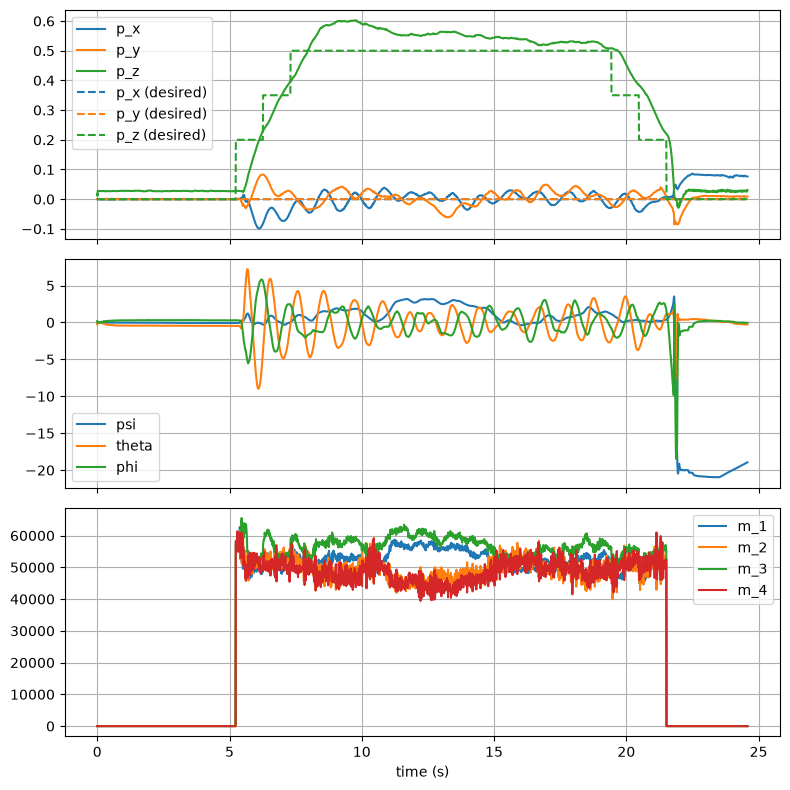

In [1000]:
fig, (ax_pos, ax_ori, ax_pow) = plt.subplots(3, 1, figsize=(8, 8), sharex=True, tight_layout=True)
px = ax_pos.plot(t, p_x, label=f'p_x')
py = ax_pos.plot(t, p_y, label=f'p_y')
pz = ax_pos.plot(t, p_z, label=f'p_z')
ax_pos.plot(t, p_x_des, '--', label=f'p_x (desired)', color=px[0].get_color())
ax_pos.plot(t, p_y_des, '--', label=f'p_y (desired)', color=py[0].get_color())
ax_pos.plot(t, p_z_des, '--', label=f'p_z (desired)', color=pz[0].get_color())
ax_pos.legend()
ax_pos.grid()
ax_ori.plot(t, psi, label='psi')
ax_ori.plot(t, theta, label='theta')
ax_ori.plot(t, phi, label='phi')
ax_ori.legend()
ax_ori.grid()
ax_pow.plot(t, m_1, label='m_1')
ax_pow.plot(t, m_2, label='m_2')
ax_pow.plot(t, m_3, label='m_3')
ax_pow.plot(t, m_4, label='m_4')
ax_pow.legend()
ax_pow.grid()
ax_pow.set_xlabel('time (s)')
plt.show()

Show the gains that were used to produce these results.

In [1001]:
show_gains(filename)

Control gains, designed 2026-10-13T18:45:49:
tau_x_cmd:     eq   0.0000    p_y  -0.0039    phi   0.0044    v_y  -0.0018    w_x   0.0006  tau_x   1.3782    e_y  -0.0024
tau_y_cmd:     eq   0.0000    p_x   0.0039  theta   0.0044    v_x   0.0018    w_y   0.0006  tau_y   1.3846    e_x   0.0024
    tau_z:     eq   0.0000    psi   0.0037    w_z   0.0005
      f_z:     eq   0.3139    p_z   0.1393    v_z   0.0946    e_z   0.0243


# 6. Summarize results

In [1002]:
only_in_flight(data_drone, t_interval=10.)

# Re-parse data so RMSE uses only the truncated in-flight interval
t = data_drone['time']
p_x = data_drone['stateEstimate.x']
p_y = data_drone['stateEstimate.y']
p_z = data_drone['stateEstimate.z']
p_x_des = data_drone['ae483log.p_x_des']
p_y_des = data_drone['ae483log.p_y_des']
p_z_des = data_drone['ae483log.p_z_des']
psi = np.deg2rad(data_drone['stateEstimate.yaw'])
theta = - np.deg2rad(data_drone['stateEstimate.pitch'])
phi = np.deg2rad(data_drone['stateEstimate.roll'])

p_x_rmse = np.sqrt(np.mean((p_x - p_x_des)**2))
p_y_rmse = np.sqrt(np.mean((p_y - p_y_des)**2))
p_z_rmse = np.sqrt(np.mean((p_z - p_z_des)**2))
psi_rmse = np.sqrt(np.mean((psi - 0.)**2))
theta_rmse = np.sqrt(np.mean((theta - 0.)**2))
phi_rmse = np.sqrt(np.mean((phi - 0.)**2))

key_changes = 'None (controller from Lab 5)'
print(f'| {flight_number} | {p_x_rmse:.3f} | {p_y_rmse:.3f} | {p_z_rmse:.3f} | {psi_rmse:.3f} | {theta_rmse:.3f} | {phi_rmse:.3f} | {key_changes} |')

# Store this flight's RMSE values [p_x, p_y, p_z, psi, theta, phi]
try:
    flight_rmse
except NameError:
    flight_rmse = {}
flight_rmse[flight_number] = [p_x_rmse, p_y_rmse, p_z_rmse, psi_rmse, theta_rmse, phi_rmse]
flight_rmse

| 4 | 0.018 | 0.026 | 0.060 | 0.032 | 0.030 | 0.024 | None (controller from Lab 5) |


{1: [np.float64(0.23682628246730975),
  np.float64(0.08642162822998778),
  np.float64(0.03563698993706214),
  np.float64(0.35374797023347165),
  np.float64(0.021904430359531782),
  np.float64(0.02534703247863989)],
 2: [np.float64(0.021579061599209654),
  np.float64(0.028784091976974027),
  np.float64(0.044633615596164515),
  np.float64(0.022327428977268516),
  np.float64(0.03151949460396786),
  np.float64(0.03517559563273822)],
 3: [np.float64(0.15511778979625818),
  np.float64(0.13866952163179835),
  np.float64(0.05783498614900946),
  np.float64(0.3039223668787629),
  np.float64(0.023474741761863024),
  np.float64(0.02730064962997748)],
 4: [np.float64(0.01842133093839883),
  np.float64(0.025600820975837095),
  np.float64(0.06031913428830842),
  np.float64(0.03223413044794662),
  np.float64(0.03045603742935237),
  np.float64(0.02390573858506683)]}

| Flight Number | RMSE in $p_x$ | RMSE in $p_y$ | RMSE in $p_z$ | RMSE in $\psi$ | RMSE in $\theta$ | RMSE in $\phi$ | Key Changes |
| :--: | :--: | :--: | :--: | :--: | :--: | :--: | :-- |
| BENCHMARK | 0.021 | 0.020 | 0.053 | 0.058 | 0.031 | 0.026 | DEFAULT CONTROLLER |
| 1 | 0.235 | 0.099 | 0.070 | 20.436 | 2.807 | 1.558 | None (controller from Lab 5) |
| 3 | 0.155 | 0.139 | 0.058 | 0.304 | 0.023 | 0.027 | None (controller from Lab 5) |
| etc. |||||||| 


In [1003]:
# Verify requirements are met, beter performance than benchmark
rmse_names = ['p_x', 'p_y', 'p_z', 'psi', 'theta', 'phi']

# Default controller RMSE values (BENCHMARK row of the table above)
benchmark_rmse = [0.021, 0.020, 0.053, 0.058, 0.031, 0.026]

def evaluate_flight(custom_rmse, benchmark_rmse=benchmark_rmse):
    # mu_k = RMSE (custom) / RMSE (default) for each k, mu = worst-case ratio
    mu_k = np.array(custom_rmse) / np.array(benchmark_rmse)
    mu = np.max(mu_k)
    grade = min(20. / mu, 40.)
    for name, ratio in zip(rmse_names, mu_k):
        print(f'  mu_{name:5s} = {ratio:8.3f}  {"OK" if ratio <= 1. else "WORSE"}')
    print(f'  mu = max(mu_k) = {mu:.3f} (worst: {rmse_names[np.argmax(mu_k)]})')
    print(f'  requirements met (mu <= 1): {mu <= 1.}')
    print(f'  grade = min(20 / mu, 40) = {grade:.2f} points')
    return mu, grade

for n, rmse in flight_rmse.items():
    print(f'Flight {n}:')
    evaluate_flight(rmse)

Flight 1:
  mu_p_x   =   11.277  WORSE
  mu_p_y   =    4.321  WORSE
  mu_p_z   =    0.672  OK
  mu_psi   =    6.099  WORSE
  mu_theta =    0.707  OK
  mu_phi   =    0.975  OK
  mu = max(mu_k) = 11.277 (worst: p_x)
  requirements met (mu <= 1): False
  grade = min(20 / mu, 40) = 1.77 points
Flight 2:
  mu_p_x   =    1.028  WORSE
  mu_p_y   =    1.439  WORSE
  mu_p_z   =    0.842  OK
  mu_psi   =    0.385  OK
  mu_theta =    1.017  WORSE
  mu_phi   =    1.353  WORSE
  mu = max(mu_k) = 1.439 (worst: p_y)
  requirements met (mu <= 1): False
  grade = min(20 / mu, 40) = 13.90 points
Flight 3:
  mu_p_x   =    7.387  WORSE
  mu_p_y   =    6.933  WORSE
  mu_p_z   =    1.091  WORSE
  mu_psi   =    5.240  WORSE
  mu_theta =    0.757  OK
  mu_phi   =    1.050  WORSE
  mu = max(mu_k) = 7.387 (worst: p_x)
  requirements met (mu <= 1): False
  grade = min(20 / mu, 40) = 2.71 points
Flight 4:
  mu_p_x   =    0.877  OK
  mu_p_y   =    1.280  WORSE
  mu_p_z   =    1.138  WORSE
  mu_psi   =    0.556  OK

# 7. Enable smooth motion

## 7.1 Results of non-smooth square flight

## 7.2 Results of smooth square flight

## 7.3 Comparison between non-smooth and smooth flight

| Flight | RMSE in $p_x$ | RMSE in $p_y$ | RMSE in $p_z$ | RMSE in $\psi$ | RMSE in $\theta$ | RMSE in $\phi$ |
| :--: | :--: | :--: | :--: | :--: | :--: | :--: |
| Hover | 0.235 | 0.099 | 0.070 | 20.436 | 2.807 | 1.558 | None (controller from Lab 5) |
| Square | 0.123 | 0.456 | 0.789 | 0.789 | 0.456 | 0.123 |
| Smooth square | 0.123 | 0.456 | 0.789 | 0.789 | 0.456 | 0.123 |